# Steam library dataset — exploratory analysis

The data behind the [recommendation model](README.md): Steam libraries with
playtime, collected through the Steam Web API, and per-game content features
from the Steam Store API and SteamSpy.

Each section asks one question and ends with what the answer means for the
model. The point is the decisions, not the plots.

1. Shape of the data
2. How concentrated is popularity?
3. Is playtime a better signal than ownership?
4. How far is this sample from Steam as a whole?
5. Content features
6. Which games go together?
7. What this means for the model

## Setup

Steam IDs identify real people, so they are replaced with anonymous integers
on load and never appear in any output of this notebook. The data files are not
included in this repository (Steam IDs are personal data); the scripts in the README
rebuild them.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path(".")
INTERACTIONS = DATA / "steam_users_games_clean.csv"
FEATURES = DATA / "game_features_v2.csv"
STEAMSPY = DATA / "steamspy_raw.jsonl"

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams["figure.figsize"] = (8, 4)

In [2]:
inter = pd.read_csv(INTERACTIONS)
inter["user"] = pd.factorize(inter["steamid"])[0]
inter = inter.drop(columns="steamid")

games = pd.read_csv(FEATURES)
inter.head()

,game_id,game_name,playtime_hours,playtime_pct,user
0,10,Counter-Strike,0.60,0.30,0
1,20,Team Fortress Classic,0.45,0.59,0
2,50,Half-Life: Opposing Force,11.33,0.84,0
3,70,Half-Life,6.77,0.61,0
4,130,Half-Life: Blue Shift,0.05,0.11,0


## 1. Shape of the data

How many users and games are there, how big is a typical library, and how is
playtime distributed?

In [3]:
n_users = inter["user"].nunique()
n_games = inter["game_id"].nunique()
print(f"{len(inter):,} library records · {n_users:,} users · {n_games:,} games")
print(f"density: {len(inter) / (n_users * n_games):.2%} of all user–game pairs are owned")

820,702 library records · 5,406 users · 23,506 games
density: 0.65% of all user–game pairs are owned


In [4]:
per_user = inter.groupby("user").size()
per_user.describe(percentiles=[.1, .25, .5, .75, .9, .99])

count   5,406.00
mean      151.81
std       167.48
min         1.00
10%        23.00
25%        52.00
50%       111.00
75%       197.00
90%       311.00
99%       793.40
max     3,075.00
dtype: float64

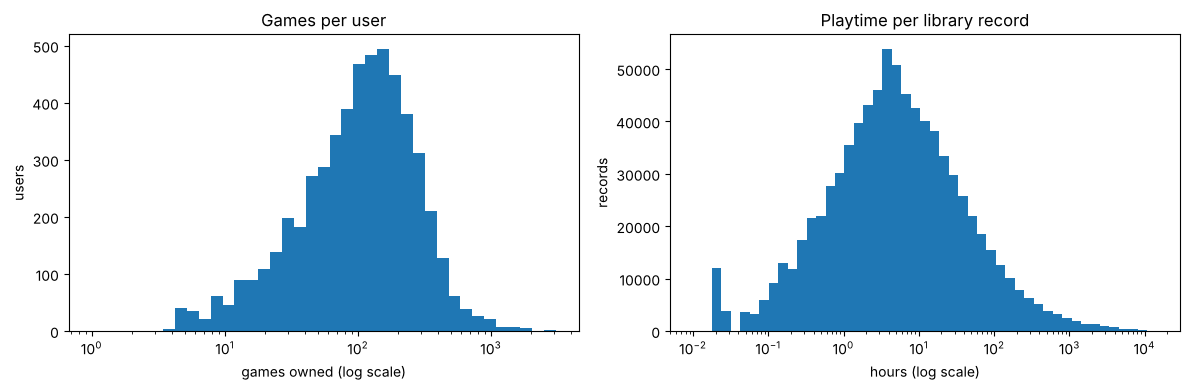

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(per_user, bins=np.logspace(0, np.log10(per_user.max()), 40))
ax[0].set_xscale("log")
ax[0].set(title="Games per user", xlabel="games owned (log scale)", ylabel="users")

hours = inter["playtime_hours"].clip(lower=0.01)
ax[1].hist(hours, bins=np.logspace(-2, np.log10(hours.max()), 50))
ax[1].set_xscale("log")
ax[1].set(title="Playtime per library record", xlabel="hours (log scale)", ylabel="records")

plt.tight_layout()

In [6]:
for h in [0.1, 1, 2, 5, 10, 100]:
    print(f"played >= {h:>5} h : {(inter['playtime_hours'] >= h).mean():6.1%} of records")

played >=   0.1 h :  96.8% of records
played >=     1 h :  78.3% of records
played >=     2 h :  67.4% of records
played >=     5 h :  48.4% of records
played >=    10 h :  35.2% of records
played >=   100 h :   7.6% of records


In [7]:
(inter.nlargest(10, "playtime_hours")[["game_name", "playtime_hours"]]
      .assign(years_nonstop=lambda d: d["playtime_hours"] / 24 / 365))

,game_name,playtime_hours,years_nonstop
514761,YoloMouse,"14,560.48",1.66
1430,Garry's Mod,"14,269.75",1.63
15160,Garry's Mod,"14,269.75",1.63
42681,Garry's Mod,"14,269.75",1.63
51396,Garry's Mod,"14,269.75",1.63
85004,Garry's Mod,"14,269.75",1.63
92464,Garry's Mod,"14,269.75",1.63
94486,Garry's Mod,"14,269.75",1.63
104484,Garry's Mod,"14,269.75",1.63
105712,Garry's Mod,"14,269.75",1.63


In [8]:
max_h = inter.groupby("game_id")["playtime_hours"].transform("max")
on_max = inter[inter["playtime_hours"] == max_h].groupby("game_id").size()

gmod = inter.loc[inter["game_name"] == "Garry's Mod", "playtime_hours"]
print(f"Garry's Mod: {(gmod == gmod.max()).sum()} of {len(gmod):,} owners at exactly {gmod.max():,.2f} h")

big = inter.groupby("game_id").size().loc[lambda s: s >= 200].index
print(f"games with 200+ owners where 2+ records tie at the maximum: {(on_max.reindex(big) >= 2).mean():.0%}"
      f" · median share of owners on the maximum: {(on_max.reindex(big) / inter.groupby('game_id').size().reindex(big)).median():.1%}")

Garry's Mod: 41 of 4,080 owners at exactly 14,269.75 h
games with 200+ owners where 2+ records tie at the maximum: 100% · median share of owners on the maximum: 1.1%


**Takeaway.** Libraries are big and very uneven. The median user owns 111 games,
the top 1% own more than 790, and one owns 3,075. Playtime per record runs from
minutes to over 14,000 hours, and 32.6% of records are under two hours: games that
came in a bundle or for free and were barely started. Ownership on its own mixes
real preferences with that filler, which is why the model only counts a game as a
positive after two hours of play.

The longest-playtime list shows the cleaning, not the players. Nine of the top ten
are Garry's Mod at exactly 14,269.75 h, and 41 Garry's Mod owners sit on that value.
`clean_interactions.py` caps each game's playtime at its 99th percentile, so
everyone above the cap gets the same number; every game with 200+ owners has ties at
its maximum. The cap removes absurd values like years of idling, but above it
playtime carries no information. The top entry, YoloMouse, is a cursor changer, not
a game: the first of several non-games in the data (see section 3).

## 2. How concentrated is popularity?

A recommender has to cope with the long tail: a few games owned by everyone,
thousands owned by almost nobody. How extreme is it here?

**What share of all library records belongs to the top 1% and top 10% most-owned games?**

In [9]:
owners = inter.groupby("game_id").size().sort_values(ascending=False)
cum_share = owners.cumsum() / owners.sum()

for pct in [0.01, 0.10]:
    k = int(np.ceil(pct * len(owners)))
    print(f"top {pct:>4.0%} of games ({k:>5,}) hold {cum_share.iloc[k - 1]:6.1%} of library records")

top   1% of games (  236) hold  34.5% of library records
top  10% of games (2,351) hold  79.0% of library records


**How unequal is ownership across games? Lorenz curve and Gini coefficient of owners per game.**

Gini coefficient: 0.850


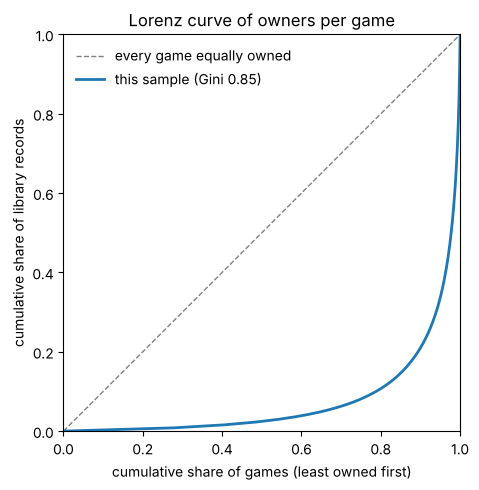

In [10]:
trapezoid = np.trapezoid if hasattr(np, "trapezoid") else np.trapz

asc = np.sort(owners.to_numpy())
x = np.concatenate([[0], np.arange(1, len(asc) + 1) / len(asc)])
y = np.concatenate([[0], np.cumsum(asc) / asc.sum()])
gini = 1 - 2 * trapezoid(y, x)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "--", color="grey", lw=1, label="every game equally owned")
ax.plot(x, y, lw=2, label=f"this sample (Gini {gini:.2f})")
ax.set(title="Lorenz curve of owners per game",
       xlabel="cumulative share of games (least owned first)",
       ylabel="cumulative share of library records",
       xlim=(0, 1), ylim=(0, 1))
ax.set_aspect("equal")
ax.legend(loc="upper left", frameon=False)
plt.tight_layout()

print(f"Gini coefficient: {gini:.3f}")

**How many games have at least 5, 10 and 20 owners?**

In [11]:
for k in [5, 10, 20]:
    n_at_least = (owners >= k).sum()
    print(f">= {k:>2} owners: {n_at_least:>6,} games ({(owners >= k).mean():5.1%})"
          f"  ·  below {k}: {(owners < k).mean():5.1%}")

>=  5 owners: 11,015 games (46.9%)  ·  below 5: 53.1%
>= 10 owners:  7,614 games (32.4%)  ·  below 10: 67.6%
>= 20 owners:  5,038 games (21.4%)  ·  below 20: 78.6%


**Takeaway.** Popularity is extremely concentrated. The top 1% of games (236 titles)
hold 34.5% of all library records and the top 10% hold 79.0%; the Gini coefficient is
0.85. At the other end, 67.6% of games have fewer than 10 owners, close to the 72%
measured on the training users, so two-thirds of the catalogue falls into the model's
shared cold-start slot. That is why "recommend the most popular games" is hard to
beat: a third of everything people own is one of 236 games, so a fixed list of them
scores many hits without knowing anything about the user. A model only adds value in
the tail, which is exactly where it has the least data.

## 3. Is playtime a better signal than ownership?

Owning a game says little on its own: bundles, giveaways and free-to-play
downloads all land in libraries. Which games are owned widely but barely played?

**Which widely owned games (50+ owners) have the lowest median playtime?**

In [12]:
per_game = inter.groupby("game_id").agg(
    owners=("user", "size"),
    median_h=("playtime_hours", "median"),
    played_2h=("playtime_hours", lambda s: (s >= 2).mean()),
    name=("game_name", "first"),
)
popular = per_game[per_game["owners"] >= 50]
print(f"{len(popular):,} games have 50+ owners")

popular.nsmallest(15, "median_h")[["name", "owners", "median_h", "played_2h"]]

2,668 games have 50+ owners


,name,owners,median_h,played_2h
game_id,,,,
247120,Portal 2 Sixense Perceptual Pack,75,0.02,0.04
325180,AppGameKit Classic,53,0.07,0.15
60,Ricochet,311,0.10,0.09
40,Deathmatch Classic,214,0.15,0.14
7760,X-COM: UFO Defense,50,0.16,0.12
250600,The Plan,55,0.20,0.00
457420,Surgeon Simulator VR: Meet The Medic,64,0.20,0.02
285330,RollerCoaster Tycoon 2: Triple Thrill Pack,99,0.22,0.23
362300,Just Survive Test Server,79,0.22,0.10


**How many records does the 2-hour threshold remove, and how does it change library size per user?**

2-hour threshold removes 267,164 of 820,702 records (32.6%)
users left with no positives: 1  ·  with fewer than 5: 89


,all owned,played >= 2 h
count,"5,406.00","5,406.00"
mean,151.81,102.39
std,167.48,114.42
min,1.00,0.00
10%,23.00,15.00
25%,52.00,34.00
50%,111.00,76.00
75%,197.00,136.00
90%,311.00,212.00
max,"3,075.00","2,514.00"


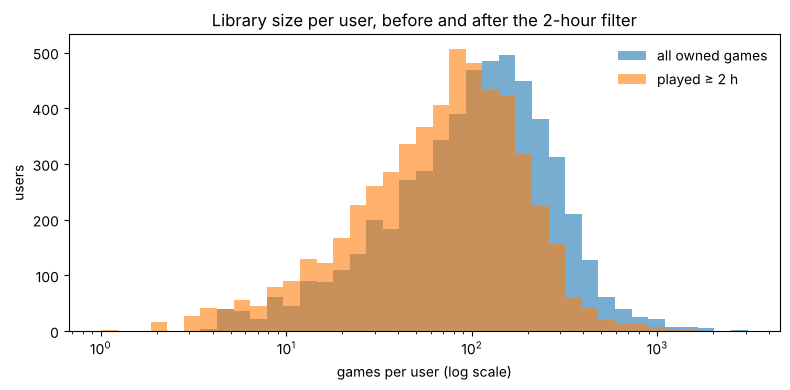

In [13]:
positives = inter[inter["playtime_hours"] >= 2]
removed = len(inter) - len(positives)
print(f"2-hour threshold removes {removed:,} of {len(inter):,} records ({removed / len(inter):.1%})")

before = inter.groupby("user").size()
after = positives.groupby("user").size().reindex(before.index, fill_value=0)
print(f"users left with no positives: {(after == 0).sum():,}  ·  with fewer than 5: {(after < 5).sum():,}")

bins = np.logspace(0, np.log10(before.max()), 40)
fig, ax = plt.subplots()
ax.hist(before, bins=bins, alpha=0.6, label="all owned games")
ax.hist(after[after > 0], bins=bins, alpha=0.6, label="played ≥ 2 h")
ax.set_xscale("log")
ax.set(title="Library size per user, before and after the 2-hour filter",
       xlabel="games per user (log scale)", ylabel="users")
ax.legend(frameon=False)
plt.tight_layout()

pd.DataFrame({"all owned": before, "played >= 2 h": after}).describe(percentiles=[.1, .25, .5, .75, .9])

In [14]:
import ast

gid = "game_id" if "game_id" in games.columns else "appid"
SOFTWARE_GENRES = {"Utilities", "Design & Illustration", "Animation & Modeling", "Video Production",
                   "Audio Production", "Software Training", "Photo Editing", "Web Publishing",
                   "Game Development", "Education", "Accounting"}

def genre_set(value):
    return set(ast.literal_eval(value)) if isinstance(value, str) and value.strip() else set()

genre_sets = games.set_index(gid)["genres"].apply(genre_set)
software = genre_sets[genre_sets.apply(lambda s: bool(s) and s <= SOFTWARE_GENRES)].index
soft = inter[inter["game_id"].isin(software)]
in_libraries = soft["game_id"].unique()

print(f"apps in the libraries with only software genres: {len(in_libraries):,}"
      f" · {len(soft):,} records ({len(soft) / len(inter):.1%})")
print(f"their Steam type: {games.loc[games[gid].isin(in_libraries), 'type'].value_counts().to_dict()}")
print(f"records of test servers (by name): {inter['game_name'].str.contains('Test Server', na=False).sum():,}")
soft["game_name"].value_counts().head(10)

apps in the libraries with only software genres: 347 · 6,054 records (0.7%)
their Steam type: {'game': 347}
records of test servers (by name): 335


game_name
Blender                  1020
Soundpad                  844
Easy eSports              303
3DMark                    283
OVR Advanced Settings     228
Lossless Scaling          204
EVGA Precision X1         193
Fuse                      160
OVR Toolkit               157
Aseprite                  124
Name: count, dtype: int64

**Takeaway.** "Played at least 2 hours" is the better label. The widely owned games
with the lowest median playtime are mostly things that came with something else:
GoldSrc bundle titles (Ricochet, Deathmatch Classic, Day of Defeat), DOOM II from
a series pack, and an add-on (Portal 2 Sixense Perceptual Pack). At most a third of
their owners reach 2 hours (Ricochet: 9%), so counting ownership would teach the model
that people like bundle filler. The filter costs 32.6% of records, but the median
library is still 76 games and only 89 users are left with fewer than 5 positives.

The threshold also has a behavioural meaning: Steam refunds a game bought in the last
14 days with less than 2 hours of playtime, so a game played past 2 hours is one the
buyer decided to keep. That argument covers only games bought on Steam. Free games,
giveaways and keys bought outside Steam cannot be refunded, and in a Steam bundle the
2 hours count across the whole bundle, so an untouched item stays when the rest was
played: exactly the titles on the list above. For them, 2 hours is still a sensible
signal threshold, but not a refund decision. Refunded games also leave the library, so
every record under 2 hours is a game its owner could not or did not bother to return.

The same list shows that Steam's `type == "game"` does not separate games from other
apps. AppGameKit Classic and VTuber Maker are software, and Just Survive Test Server is
a test build. Apps whose genres are all software genres add up to 347 apps and 6,054
records (0.7%), led by Blender, Soundpad and 3DMark, all typed "game" by Steam; 335 more
records are test servers. That count is a lower bound, since YoloMouse and Wallpaper
Engine also carry game genres. The volume is small, but these should be filtered out by
genre, name or a manual list before training.

## 4. How far is this sample from Steam as a whole?

Users were found by crawling friends lists from five accounts, so they are one
social network, not a random sample. SteamSpy estimates how many people own each
game across all of Steam — compare the two to measure the bias directly.

In [15]:
spy = pd.read_json(STEAMSPY, lines=True)
spy = spy[spy["ok"] == True][["appid", "name", "owners"]].copy()
spy.head()

,appid,name,owners
0,10,Counter-Strike,"10,000,000 .. 20,000,000"
1,20,Team Fortress Classic,"1,000,000 .. 2,000,000"
2,30,Day of Defeat,"5,000,000 .. 10,000,000"
3,40,Deathmatch Classic,"5,000,000 .. 10,000,000"
4,50,Half-Life: Opposing Force,"2,000,000 .. 5,000,000"


**How many owners does each game have across Steam, and how many in this sample?**

In [16]:
spy = spy.drop_duplicates("appid").copy()
bounds = (spy["owners"].astype(str)
          .str.replace(",", "", regex=False)
          .str.split(" .. ", expand=True)
          .astype(float))
spy["low"], spy["high"] = bounds[0], bounds[1]
spy["global_owners"] = np.sqrt(spy["low"].clip(lower=1) * spy["high"])

df = spy.merge(owners.rename("sample_owners"), left_on="appid", right_index=True, how="left")
df["sample_owners"] = df["sample_owners"].fillna(0).astype(int)
print(f"{len(spy):,} SteamSpy games · {(df['sample_owners'] > 0).sum():,} of them owned by someone in the sample"
      f" · {owners.index.isin(spy['appid']).mean():.1%} of sample games have a SteamSpy entry")

df = df[df["low"] >= 20_000].copy()
print(f"{len(df):,} games with a global low bound of at least 20,000")
df.sort_values("global_owners", ascending=False).head(10)[["name", "owners", "global_owners", "sample_owners"]]

24,678 SteamSpy games · 23,419 of them owned by someone in the sample · 99.6% of sample games have a SteamSpy entry
16,044 games with a global low bound of at least 20,000


,name,owners,global_owners,sample_owners
10656,PUBG: BATTLEGROUNDS,"100,000,000 .. 200,000,000","141,421,356.24",3036
21,Dota 2,"100,000,000 .. 200,000,000","141,421,356.24",1645
25,Counter-Strike: Global Offensive,"100,000,000 .. 200,000,000","141,421,356.24",5054
17011,Apex Legends,"100,000,000 .. 200,000,000","141,421,356.24",2141
3050,Grand Theft Auto V Legacy,"50,000,000 .. 100,000,000","70,710,678.12",2749
18,Team Fortress 2,"50,000,000 .. 100,000,000","70,710,678.12",2279
16209,New World: Aeternum,"50,000,000 .. 100,000,000","70,710,678.12",657
19523,Lost Ark,"50,000,000 .. 100,000,000","70,710,678.12",846
20935,Call of Duty: Modern Warfare II,"50,000,000 .. 100,000,000","70,710,678.12",1634
3887,Unturned,"50,000,000 .. 100,000,000","70,710,678.12",3449


**How strongly does popularity in this sample track popularity across Steam?**

Spearman rank correlation: 0.68 across 16,044 games


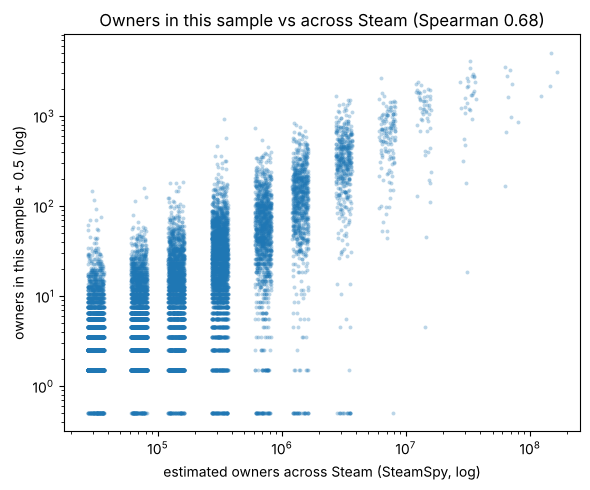

In [17]:
rho = df[["sample_owners", "global_owners"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman rank correlation: {rho:.2f} across {len(df):,} games")

rng = np.random.default_rng(0)
x_jit = df["global_owners"] * np.exp(rng.uniform(-0.15, 0.15, len(df)))

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(x_jit, df["sample_owners"] + 0.5, s=8, alpha=0.3, linewidths=0)
ax.set(xscale="log", yscale="log",
       title=f"Owners in this sample vs across Steam (Spearman {rho:.2f})",
       xlabel="estimated owners across Steam (SteamSpy, log)",
       ylabel="owners in this sample + 0.5 (log)")
plt.tight_layout()

**Which games are most over- and under-represented in this sample?**

In [18]:
sample_adj = df["sample_owners"] + 0.5
df["sample_share"] = sample_adj / sample_adj.sum()
df["global_share"] = df["global_owners"] / df["global_owners"].sum()
df["over_rep"] = np.log2(df["sample_share"] / df["global_share"])

cols = ["name", "sample_owners", "global_owners", "over_rep"]

print("Most over-represented (at least 10 owners in the sample, so one or two friends can't top the list)")
display(df[df["sample_owners"] >= 10].nlargest(20, "over_rep")[cols])

print("Most under-represented")
display(df.nsmallest(20, "over_rep")[cols])

Most over-represented (at least 10 owners in the sample, so one or two friends can't top the list)


,name,sample_owners,global_owners,over_rep
11279,Guns of Icarus Alliance,147,"31,622.78",5.74
2486,8BitMMO,117,"31,622.78",5.41
1827,BIT.TRIP Presents... Runner2: Future Legend of...,92,"31,622.78",5.07
824,ARMA 2,911,"316,227.77",5.05
8647,Unforgiving Trials: The Darkest Crusade,74,"31,622.78",4.76
909,Faerie Solitaire,70,"31,622.78",4.68
24290,Guilty as Sock!,156,"70,710.68",4.67
11788,Desert Bus VR,69,"31,622.78",4.66
16533,Onset,61,"31,622.78",4.48
20672,Arma Reforger,563,"316,227.77",4.35


Most under-represented


,name,sample_owners,global_owners,over_rep
1992,Marvel Heroes Omega,0,"7,071,067.81",-10.27
992,Call of Duty®: Modern Warfare® 3,0,"3,162,277.66",-9.11
1135,Tactical Intervention,0,"3,162,277.66",-9.11
1291,Dead Island,0,"3,162,277.66",-9.11
1443,Nosgoth,0,"3,162,277.66",-9.11
1489,Magicka: Wizard Wars,0,"3,162,277.66",-9.11
1574,Hitman: Sniper Challenge,0,"3,162,277.66",-9.11
2024,Firefall,0,"3,162,277.66",-9.11
2254,The Mighty Quest For Epic Loot,0,"3,162,277.66",-9.11
3044,HAWKEN,0,"3,162,277.66",-9.11


In [19]:
gid = "game_id" if "game_id" in games.columns else "appid"
delisted = games.loc[games["type"] == "unknown", gid]

print(f"games in the cleaned libraries: {inter['game_id'].nunique():,}"
      f" · apps typed 'game' in the features file: {(games['type'] == 'game').sum():,}")
print(f"apps the Store API cannot return (type 'unknown'): {len(delisted):,}"
      f" · of them in the cleaned libraries: {inter['game_id'].isin(delisted).sum():,}")

if "df" in globals():
    bottom = df.nsmallest(20, "over_rep")
    print(f"bottom 20 that are delisted: {bottom['appid'].isin(delisted).sum()} of 20")
    no_delisted = df[~df["appid"].isin(delisted)]
    rho_clean = no_delisted[["sample_owners", "global_owners"]].corr(method="spearman").iloc[0, 1]
    print(f"Spearman without delisted apps: {rho_clean:.2f} across {len(no_delisted):,} games")

games in the cleaned libraries: 23,506 · apps typed 'game' in the features file: 23,506
apps the Store API cannot return (type 'unknown'): 851 · of them in the cleaned libraries: 0
bottom 20 that are delisted: 19 of 20
Spearman without delisted apps: 0.72 across 15,683 games


**Takeaway.** Popularity in the sample follows Steam as a whole only moderately:
Spearman 0.68 over 16,044 games.

The over-represented end shows the friends network. The clearest cluster is military
simulation: ARMA 2 (911 owners in the sample), Arma Reforger and Carrier Command 2, all
from Bohemia Interactive, plus Tannenberg. That points to a milsim community in the
network. WARSAW RISING: City of Heroes hints at a Polish part of the network, but one
title is not enough to claim it. The rest are small titles, many of them giveaways, and
their global estimate is too coarse to rank: SteamSpy puts every game with 20,000–50,000
owners in one bucket, so all of them get the same 31,623.

The under-represented end is not about the network. 19 of the bottom 20 games have zero
owners in the sample because the cleaning step keeps only apps the Store API types as
"game", and delisted apps come back as "unknown": none of the 851 survives (cell above).
They are shut-down online games (Marvel Heroes Omega, Nosgoth, Firefall, HAWKEN, TERA) and
replaced originals (Dead Island, Titan Quest, GRID), which people still have in their
libraries but the cleaned data cannot contain. Without the delisted apps, the rank
correlation rises from 0.68 to 0.72 over 15,683 games, so part of the disagreement was
the pipeline, not the sample. The one real entry at the bottom, CyberCorp (4 owners here
against an estimate of about 14 million), is a single title and says little on its own.

For the model: it learns this network's taste. Milsim and the community's niche titles
will be pushed harder than they deserve for users outside it, and this data cannot
measure how well it works for them.

## 5. Content features

The model relies on genres, categories and tags for games too obscure to have
collaborative signal. How rich are those features, and does the catalogue look
the same as what people actually play?

**How many tags does a game have, and how many games have none?**

In [20]:
import ast

ID = "game_id" if "game_id" in games.columns else "appid"    # id column in the features file

def parse(value):
    if pd.isna(value) or str(value).strip() in ("", "[]", "{}"):
        return []
    return ast.literal_eval(value)

tags = games["tags"].apply(parse)
n_tags = tags.apply(len)

print(n_tags.describe())
print(f"\ngames with no tags: {(n_tags == 0).sum():,} of {len(games):,} ({(n_tags == 0).mean():.1%})")

count   24,918.00
mean        12.55
std          7.61
min          0.00
25%          5.00
50%         15.00
75%         20.00
max         20.00
Name: tags, dtype: float64

games with no tags: 2,851 of 24,918 (11.4%)


**Do genre shares in people's libraries match genre shares in the catalogue?**

100.0% of library records have a game in the features file


,catalogue,library records,records / catalogue
genre,,,
Massively Multiplayer,0.04,0.11,2.76
Free To Play,0.10,0.20,2.05
Action,0.44,0.65,1.50
RPG,0.21,0.23,1.10
Racing,0.04,0.04,0.99
Strategy,0.22,0.22,0.98
Simulation,0.25,0.24,0.95
Adventure,0.38,0.36,0.95
Sports,0.05,0.04,0.84


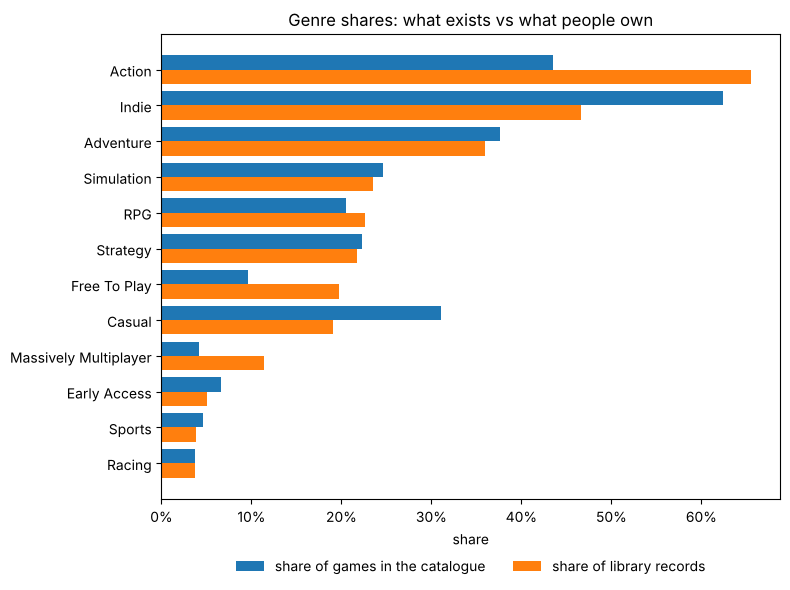

In [21]:
from matplotlib.ticker import PercentFormatter

def as_names(value):
    v = parse(value)
    if isinstance(v, dict):
        return list(v.keys())
    return [g["description"] if isinstance(g, dict) else g for g in v]

game_genre = (games[[ID]]
              .assign(genre=games["genres"].apply(as_names))
              .explode("genre")
              .dropna(subset=["genre"]))

catalogue = game_genre["genre"].value_counts() / games[ID].nunique()

with_features = inter[inter["game_id"].isin(games[ID])]
print(f"{len(with_features) / len(inter):.1%} of library records have a game in the features file")
rec_genre = with_features[["game_id"]].merge(game_genre, left_on="game_id", right_on=ID)
played_share = rec_genre["genre"].value_counts() / len(with_features)

shares = pd.DataFrame({"catalogue": catalogue, "library records": played_share}).fillna(0)
top = shares.max(axis=1).nlargest(12).index
plot_df = shares.loc[top].sort_values("library records")

pos = np.arange(len(plot_df))
h = 0.4
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(pos + h / 2, plot_df["catalogue"], height=h, label="share of games in the catalogue")
ax.barh(pos - h / 2, plot_df["library records"], height=h, label="share of library records")
ax.set_yticks(pos, plot_df.index)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(title="Genre shares: what exists vs what people own", xlabel="share")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
plt.tight_layout()

common = shares[shares.max(axis=1) >= 0.01].copy()
common["records / catalogue"] = common["library records"] / common["catalogue"]
common.sort_values("records / catalogue", ascending=False)

In [22]:
# Does the 2-hour label shrink the Free to Play excess? Same comparison, on records with 2+ hours only.
played_feat = positives[positives["game_id"].isin(games[ID])]
played_genre = played_feat[["game_id"]].merge(game_genre, left_on="game_id", right_on=ID)
played_2h_share = played_genre["genre"].value_counts() / len(played_feat)

(pd.DataFrame({
    "all records / catalogue": shares["library records"] / shares["catalogue"],
    "played ≥ 2 h / catalogue": played_2h_share / catalogue,
 })
 .reindex(common.index)
 .sort_values("played ≥ 2 h / catalogue", ascending=False))

,all records / catalogue,played ≥ 2 h / catalogue
genre,,
Massively Multiplayer,2.76,2.70
Free To Play,2.05,1.71
Action,1.50,1.53
RPG,1.10,1.18
Strategy,0.98,0.99
Adventure,0.95,0.99
Simulation,0.95,0.96
Racing,0.99,0.91
Utilities,0.81,0.86


**Takeaway.** Content features are reasonably rich: 12.6 tags per game on average,
median 15 (the cap is 20), but 2,851 games (11.4%) have none and are described by genres
and categories alone. The catalogue and the libraries look different. Massively
Multiplayer (2.8×) and Free to Play (2.1×) are far more common in libraries than in the
catalogue; Casual (0.61×) and Indie (0.75×) are rarer. The catalogue is mostly small indie
games, while people own big online games. Part of the Free to Play excess is simply that
it costs nothing to add, the same reason free titles dominate the owned-but-unplayed list
in section 3. The 2-hour label removes only part of it: on records with 2+ hours, Free to
Play falls from 2.05× to 1.71× its catalogue share, while Massively Multiplayer barely moves
(2.76× to 2.70×). Most of the online-game excess is real play, not free downloads. For the model, the content branch
mainly serves the long tail, which is the indie and casual part of the catalogue that
people own least, so its recommendations rest on the weakest evidence.

## 6. Which games go together?

Collaborative filtering only works if owning one game says something about
owning another. Before trusting a model built on that, check that the signal is
there.

**Among the 300 most-owned games, which pairs are owned together far more often than chance?**

In [23]:
top300 = owners.nlargest(300).index
sub = inter[inter["game_id"].isin(top300)]

X = pd.crosstab(sub["user"], sub["game_id"]).clip(upper=1)
co = (X.T @ X).to_numpy().astype(float)
n = np.diag(co)
U = n_users

lift = co * U / np.outer(n, n)
keep = np.triu(np.ones_like(co, dtype=bool), k=1) & (co >= 30)
i, j = np.nonzero(keep)

ids = X.columns.to_numpy()
name = per_game["name"]
pairs = (pd.DataFrame({
            "game_a": name.loc[ids[i]].to_numpy(),
            "game_b": name.loc[ids[j]].to_numpy(),
            "co_owners": co[i, j].astype(int),
            "lift": lift[i, j],
         })
         .sort_values("lift", ascending=False)
         .reset_index(drop=True))

print(f"{len(pairs):,} pairs with 30+ co-owners · median lift {pairs['lift'].median():.2f}"
      f" · {(pairs['lift'] >= 3).mean():.1%} of pairs at lift 3 or more")
pairs.head(25)

44,849 pairs with 30+ co-owners · median lift 1.42 · 0.4% of pairs at lift 3 or more


,game_a,game_b,co_owners,lift
0,Call of Duty: Black Ops,Call of Duty: Black Ops - Multiplayer,515,8.71
1,Call of Duty: Modern Warfare 2 (2009),Call of Duty: Modern Warfare 2 (2009) - Multip...,629,6.92
2,Call of Duty: Black Ops II,Call of Duty: Black Ops II - Multiplayer,692,5.86
3,"Warhammer 40,000: Darktide","Warhammer 40,000: Space Marine 2",365,4.70
4,Half-Life: Alyx,Beat Saber,330,4.44
5,Super Meat Boy,The Binding of Isaac,276,4.42
6,Pavlov VR,Beat Saber,397,4.41
7,Mount & Blade: Warband,Mount & Blade II: Bannerlord,433,4.36
8,Men of War: Assault Squad 2,Foxhole,216,4.34
9,Hollow Knight,Hades,258,4.34


In [24]:
def median_lift(users):
    s = sub[sub["user"].isin(users)]
    Xq = pd.crosstab(s["user"], s["game_id"]).clip(upper=1)
    c = (Xq.T @ Xq).to_numpy().astype(float)
    nq = np.diag(c)
    l = c * len(users) / np.outer(nq, nq)
    k = np.triu(np.ones_like(c, dtype=bool), k=1) & (c >= 30)
    return np.median(l[k]), int(k.sum())

lib = inter.groupby("user").size()
band = pd.qcut(lib, 4, labels=["smallest 25%", "25–50%", "50–75%", "largest 25%"])
groups = [("all users", lib.index),
          ("all but the largest 1%", lib.index[lib <= lib.quantile(0.99)])]
groups += [(f"{b} of libraries", lib.index[band == b]) for b in band.cat.categories]

rows = []
for label, users in groups:
    m, k = median_lift(users)
    rows.append({"users": label, "games owned": f"{lib[users].min():,}–{lib[users].max():,}",
                 "pairs with 30+ co-owners": k, "median lift": m})
pd.DataFrame(rows)

,users,games owned,pairs with 30+ co-owners,median lift
0,all users,"1–3,075",44849,1.42
1,all but the largest 1%,1–782,44847,1.41
2,smallest 25% of libraries,1–52,1358,1.28
3,25–50% of libraries,53–111,13261,1.10
4,50–75% of libraries,112–197,35355,1.05
5,largest 25% of libraries,"198–3,075",44809,1.06


**Takeaway.** Yes, the data supports collaborative filtering. The highest-lift pairs among
the 300 most-owned games are recognisable taste clusters: Warhammer 40,000: Darktide with
Space Marine 2 (lift 4.7), Half-Life: Alyx with Beat Saber and Pavlov VR (VR owners,
4.0–4.4), Hollow Knight with Hades and Hades with Balatro (indie action and roguelikes),
Crusader Kings II with Europa Universalis IV (Paradox strategy), and FTL with XCOM 2.

The three strongest pairs are not taste, though. Call of Duty: Black Ops with Black Ops –
Multiplayer (lift 8.7), and the same for Modern Warfare 2 and Black Ops II, are one
purchase that grants two appids. They are a store artifact and should be merged into one
item before training.

The median lift of 1.42 also overstates the general signal. People who own many games own
many of the top 300 at once, so library-size differences raise co-ownership of everything
with everything. Among users with similar library sizes the median lift is only 1.05–1.28
(cell above), and removing just the largest 1% of libraries barely changes it (1.41), so
this is a population-wide effect, not a few collectors. The real signal is in the
high-lift pairs, not in the median.

## 7. What this means for the model

Pull the takeaways together. For each, one line: the finding, and the modelling
decision it supports or questions.

| Finding | Decision |
| --- | --- |
| 32.6% of records are under 2 h; bundle titles have median playtime of minutes | Positive = played ≥ 2 h (also Steam's refund limit: past it, a purchase can no longer be refunded) |
| Playtime is capped at each game's 99th percentile (41 Garry's Mod owners at 14,269.75 h) | Use playtime as a threshold, not a weight; values at the cap carry no information |
| Top 1% of games hold 34.5% of records, Gini 0.85 | Popularity baseline is the bar to beat; report results on long-tail games separately |
| 67.6% of games have fewer than 10 owners | Keep the shared cold-start slot below 10 owners; content features carry these games |
| `type == "game"` lets through software (347 apps, 6,054 records) and test servers | Add a genre / name filter for non-games before training |
| Black Ops + Black Ops – Multiplayer: one purchase, two appids (lift 8.7) | Merge paired appids into one item |
| One friends network: milsim over-represented; Spearman 0.72 with Steam once delisted apps are dropped | Don't claim quality for users outside the network; evaluation only covers this population |
| 19 of the 20 least-represented games are delisted apps the type filter removes | Exclude delisted apps from any comparison with SteamSpy |
| Median lift 1.42 drops to 1.05–1.28 among users with similar library sizes | Account for library size when measuring co-occurrence |